# 02 — Exploratory data analysis

Descriptive statistics, decomposition, correlation analysis and visual outputs (Req 7.2). Narrative: `reports/eda_report.md`.

*Data: CEDA Agri Market Data, Centre for Economic Data and Analysis (CEDA), Ashoka University; original source DMI, Ministry of Agriculture and Farmers Welfare (Agmarknet).*

In [1]:
import os, sys
from pathlib import Path
# Run from the repository root so `src` and configured relative paths resolve
root = Path.cwd()
while not (root / "configs" / "config.json").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import load_config, resolve_path
cfg = load_config()
tables = resolve_path(cfg["paths"]["tables_dir"])
figs = resolve_path(cfg["paths"]["figures_dir"])
print("Repository root:", root)

Repository root: D:\MY works\CropCast


In [2]:
from src.analysis.eda import run as run_eda
summary = run_eda(cfg)
pd.read_csv(tables / 'eda_descriptive_stats.csv').round(3)

,series_id,variable,n,mean,median,std,min,q25,q75,max,cv,skewness,excess_kurtosis
0,onion_maharashtra,modal_price,2523,1388.292,1079.255,963.196,406.163,710.033,1755.569,7506.451,0.694,2.142,6.489
1,onion_maharashtra,min_price,2523,706.701,572.561,449.485,150.000,377.424,865.875,3171.783,0.636,1.749,3.635
2,onion_maharashtra,max_price,2523,1801.100,1399.861,1288.000,568.786,920.781,2292.056,10913.175,0.715,2.538,9.669
3,onion_maharashtra,arrival_qty,2523,16323.068,15664.000,9001.510,2.000,9069.000,22739.000,45648.000,0.551,0.341,-0.534
4,onion_maharashtra,log_return_modal,2522,-0.000,0.001,0.078,-0.584,-0.040,0.039,0.533,NaN,-0.116,4.968
5,potato_uttar_pradesh,modal_price,2557,1016.850,952.073,493.454,433.558,646.341,1230.341,3015.181,0.485,1.513,3.085
6,potato_uttar_pradesh,min_price,2557,967.551,897.045,484.755,405.000,597.904,1173.065,2928.705,0.501,1.524,3.080
7,potato_uttar_pradesh,max_price,2557,1078.886,1012.125,501.941,484.412,702.373,1295.904,3098.515,0.465,1.486,2.973
8,potato_uttar_pradesh,arrival_qty,2557,15363.746,14683.250,8593.779,442.000,9250.830,19919.970,113475.300,0.559,2.197,14.232
9,potato_uttar_pradesh,log_return_modal,2556,0.000,0.000,0.023,-0.204,-0.010,0.011,0.172,NaN,0.005,8.388


## Coverage, seasonality and decomposition choice

In [3]:
pd.DataFrame(summary['seasonality']).T

,acf_return_lag7,acf_return_band_95,weekday_kruskal_H,weekday_kruskal_p,acf_level_lag365,acf_level_lag182,weekly_return_acf_significant,weekday_kruskal_p_bh,weekday_effect_significant_bh
onion_maharashtra,0.308345,0.039029,254.401632,0.0,0.186616,-0.144507,True,0.0,True
potato_uttar_pradesh,0.384604,0.038768,563.628559,0.0,0.071625,0.103108,True,0.0,True


In [4]:
pd.DataFrame(summary['decomposition']).T

,yearly_mean_std_spearman,yearly_cv_min,yearly_cv_max,model,seasonal_strength,trend_strength,seasonal_peak_month,seasonal_trough_month
onion_maharashtra,0.821429,0.220413,0.902298,multiplicative,0.238324,0.308619,11,4
potato_uttar_pradesh,0.892857,0.059542,0.361989,multiplicative,0.422969,0.580162,8,2


In [5]:
pd.read_csv(tables / 'eda_weekday_profile.csv').round(2)

,series_id,weekday,days,arrival_median,log_price_dev_from_centred_7d_mean_pct,mean_abs_log_return_pct
0,onion_maharashtra,Mon,360,21054.00,-1.13,8.49
1,onion_maharashtra,Tue,364,18253.50,-0.84,4.59
2,onion_maharashtra,Wed,362,19613.00,0.27,4.55
3,onion_maharashtra,Thu,360,20067.50,-0.06,4.64
4,onion_maharashtra,Fri,359,18278.00,-1.08,4.97
5,onion_maharashtra,Sat,360,12438.50,-0.82,4.14
6,onion_maharashtra,Sun,358,6347.50,3.69,7.07
7,potato_uttar_pradesh,Mon,365,16793.70,0.34,2.40
8,potato_uttar_pradesh,Tue,365,15827.45,0.03,1.25
9,potato_uttar_pradesh,Wed,365,16095.64,0.15,1.22


## Figures

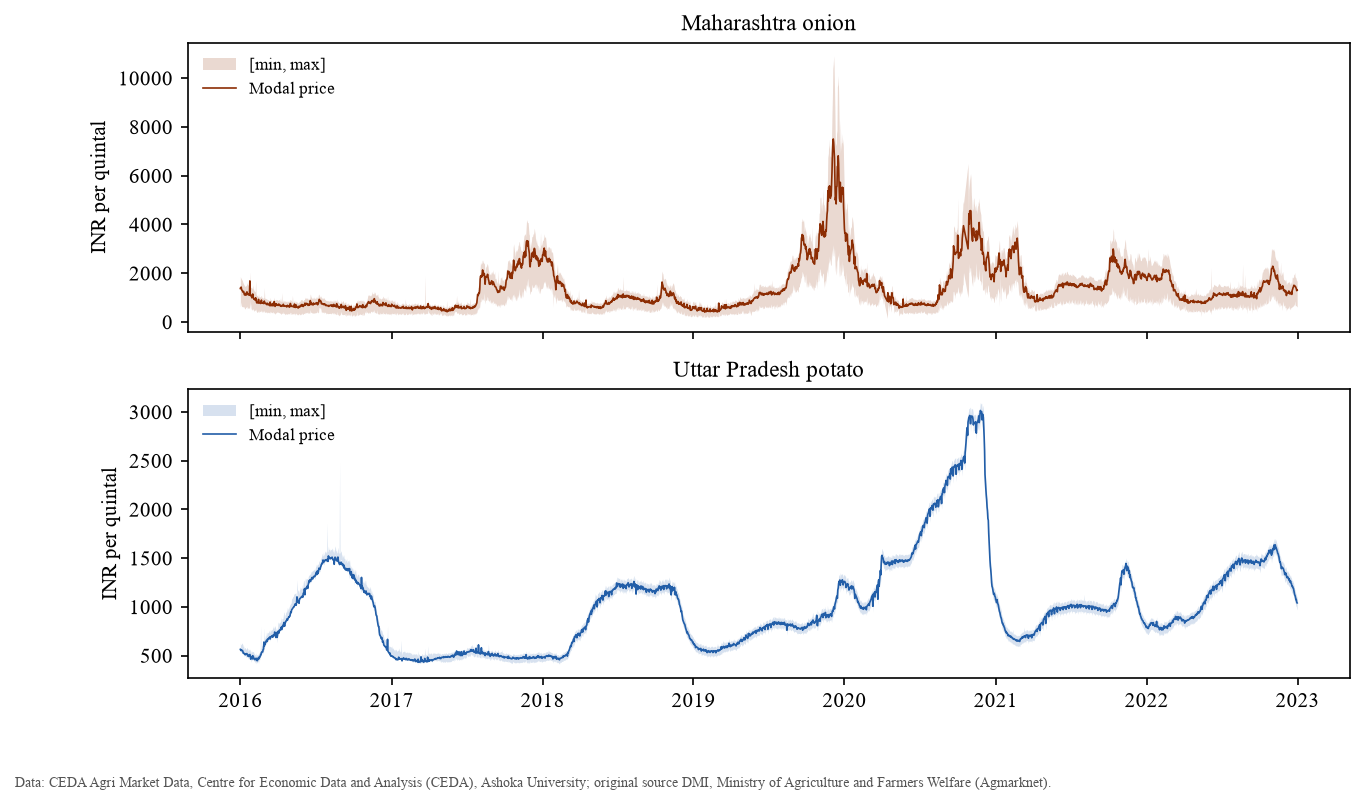

In [6]:
display(Image(filename=str(figs / 'fig01_price_series.png')))

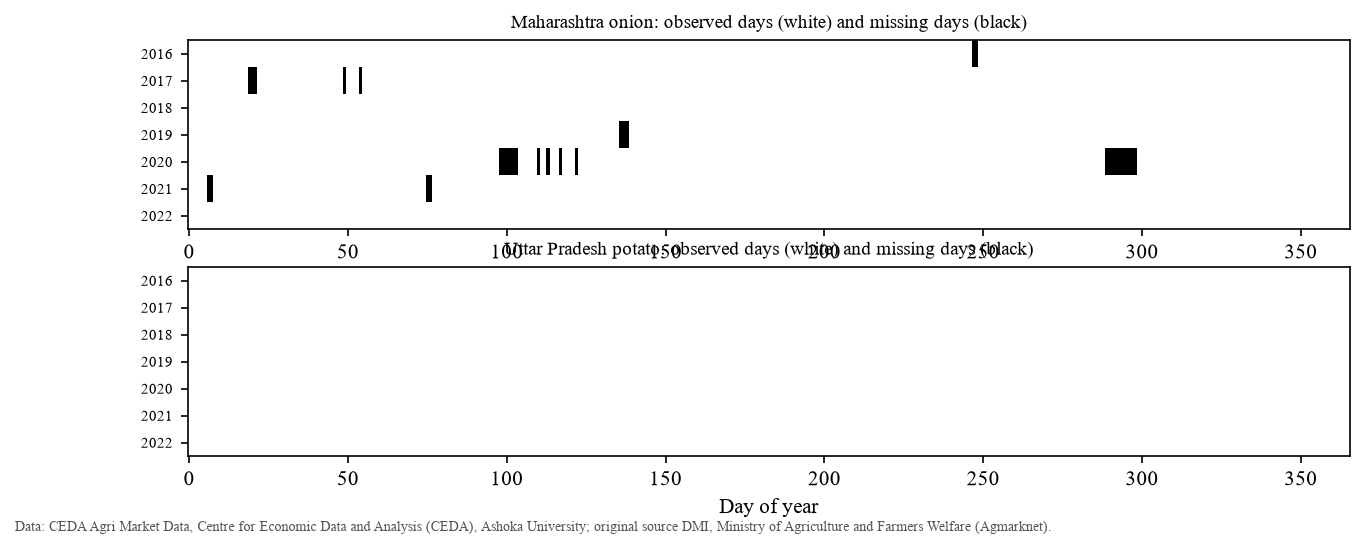

In [7]:
display(Image(filename=str(figs / 'fig03_missingness_heatmap.png')))

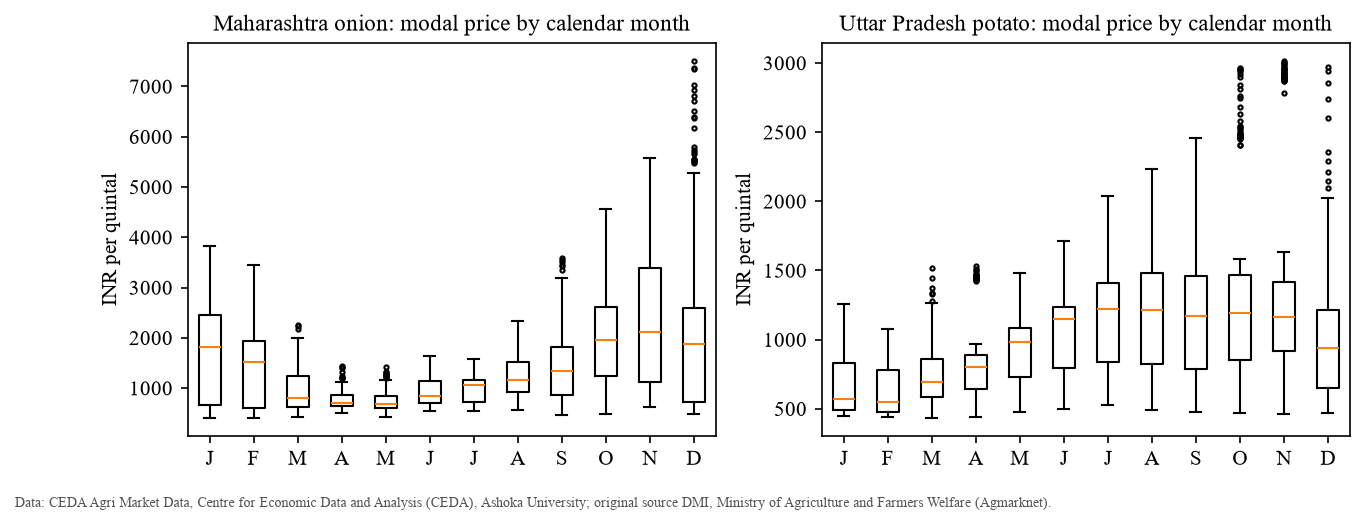

In [8]:
display(Image(filename=str(figs / 'fig04_monthly_boxplots.png')))

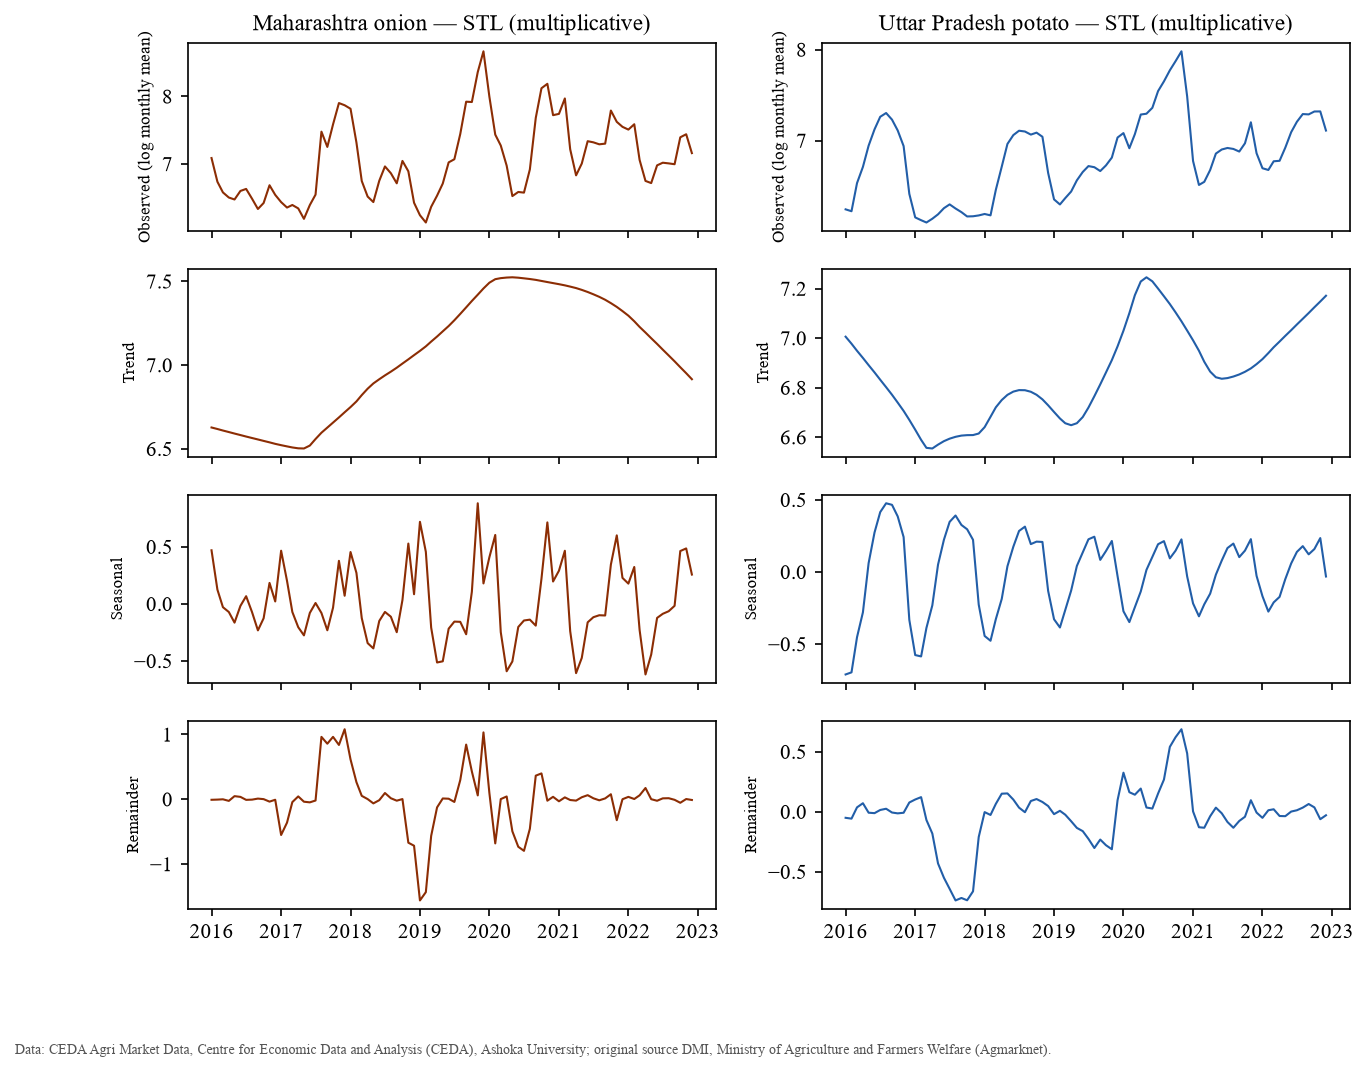

In [9]:
display(Image(filename=str(figs / 'fig05_stl_decomposition.png')))

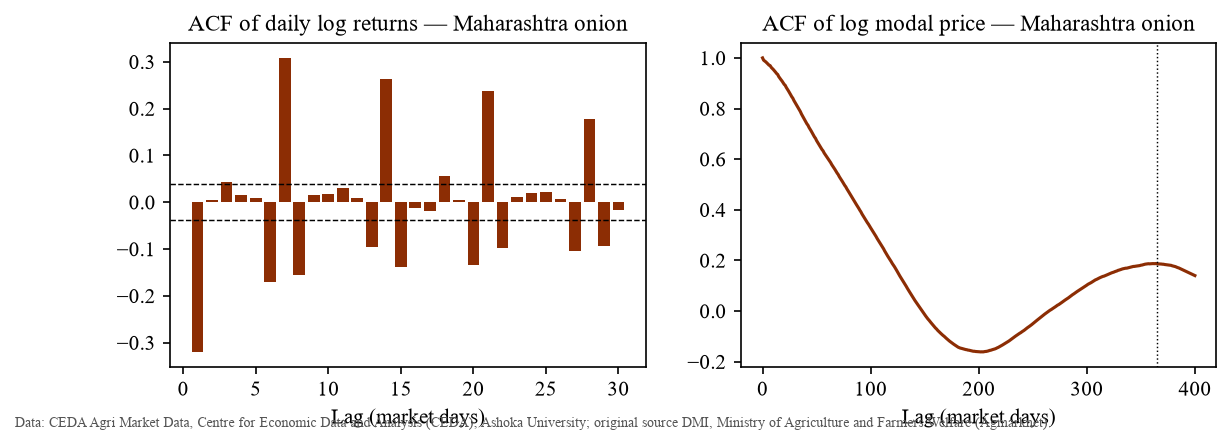

In [10]:
display(Image(filename=str(figs / 'fig06_acf_onion_maharashtra.png')))

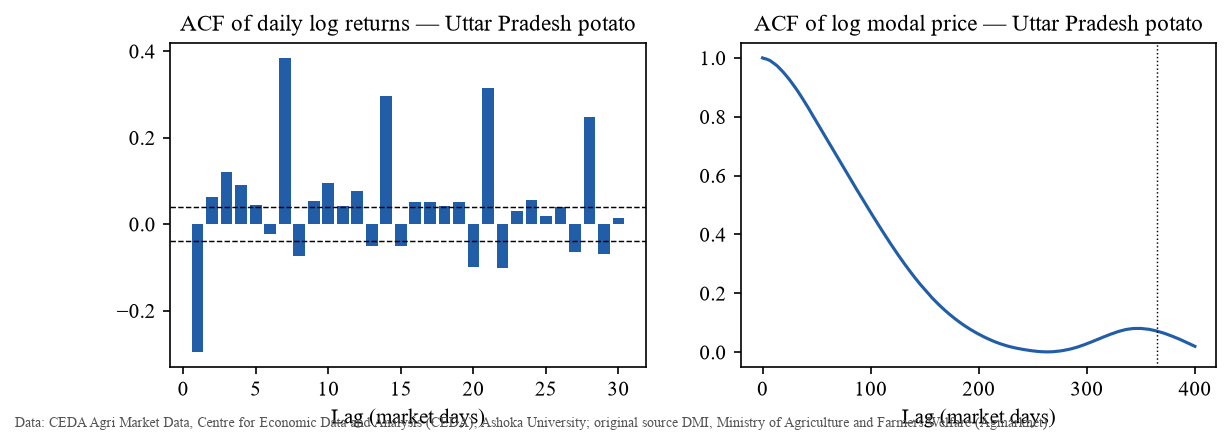

In [11]:
display(Image(filename=str(figs / 'fig06_acf_potato_uttar_pradesh.png')))

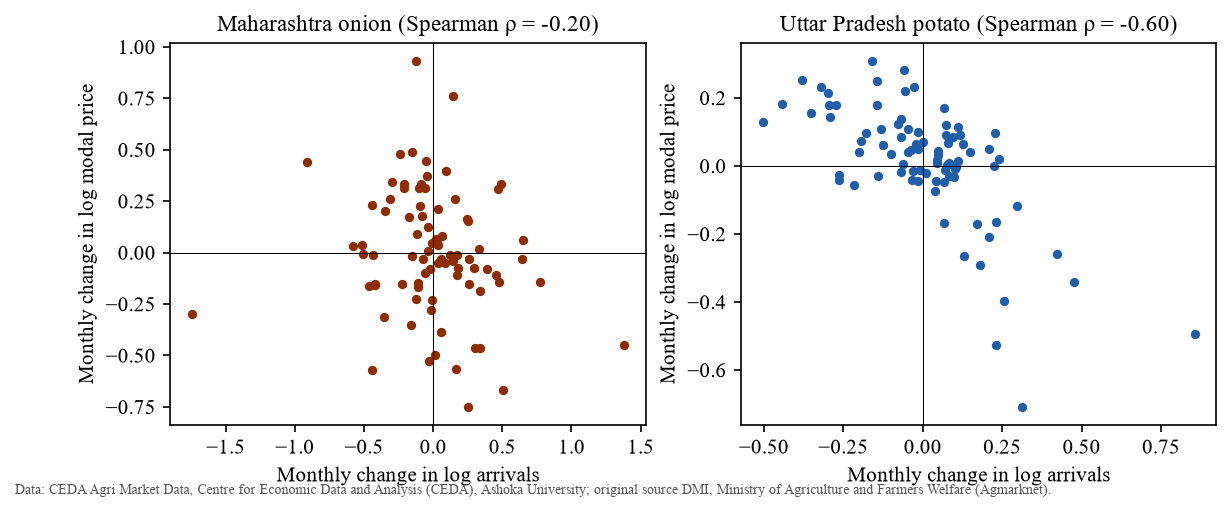

In [12]:
display(Image(filename=str(figs / 'fig08_price_arrival_monthly_changes.png')))

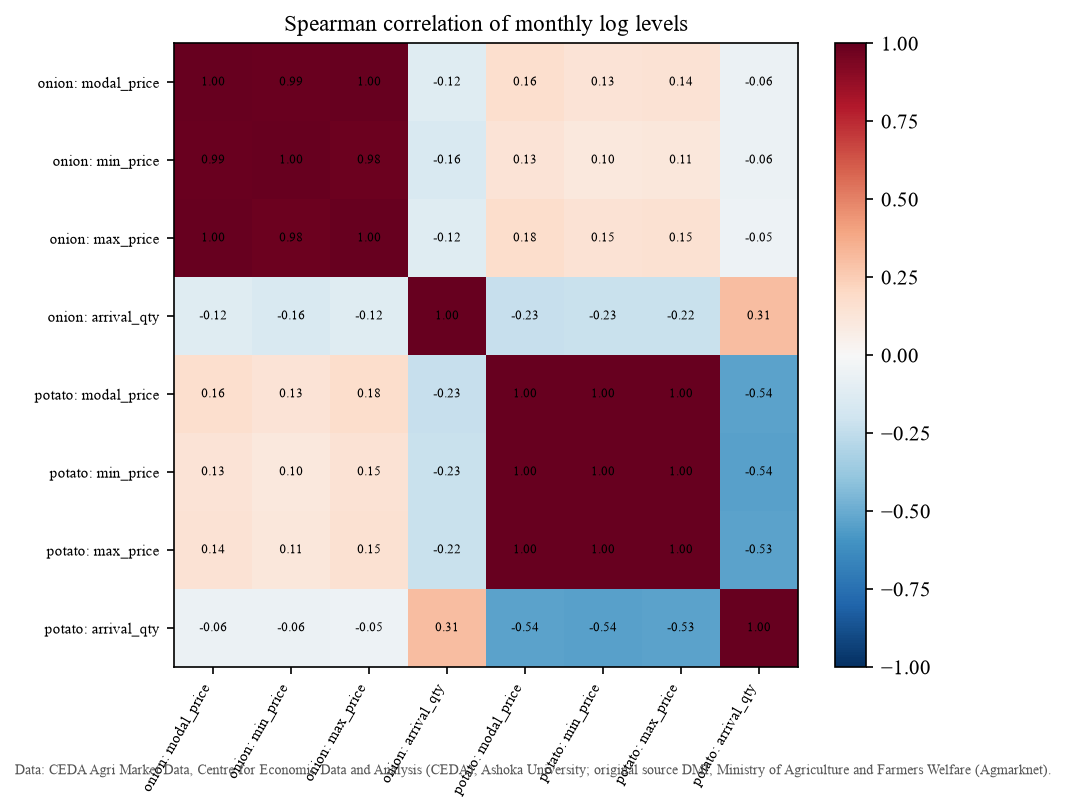

In [13]:
display(Image(filename=str(figs / 'fig09_correlation_heatmap.png')))

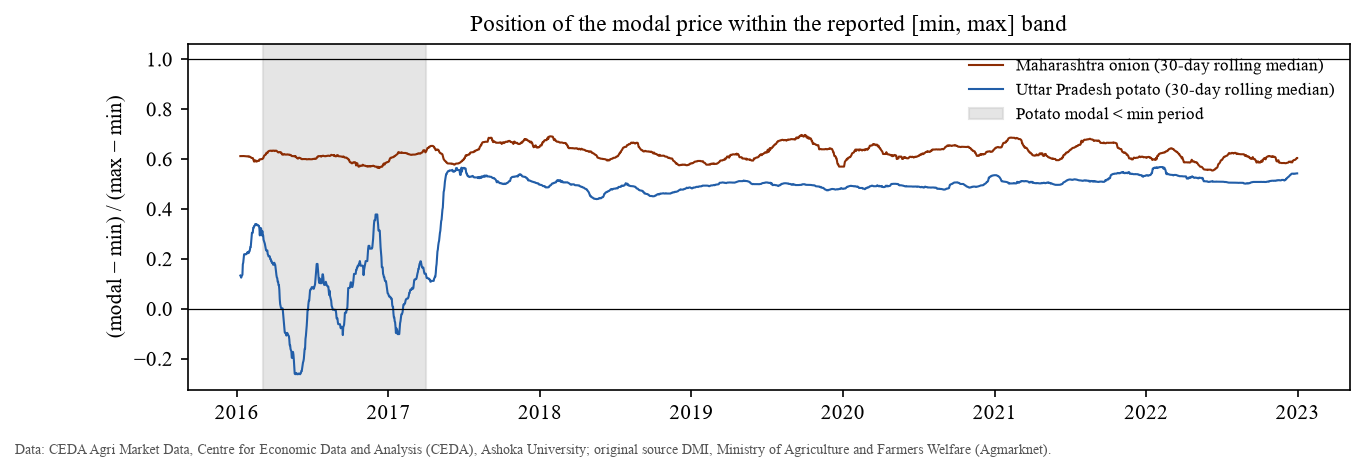

In [14]:
display(Image(filename=str(figs / 'fig10_modal_position_iss002.png')))

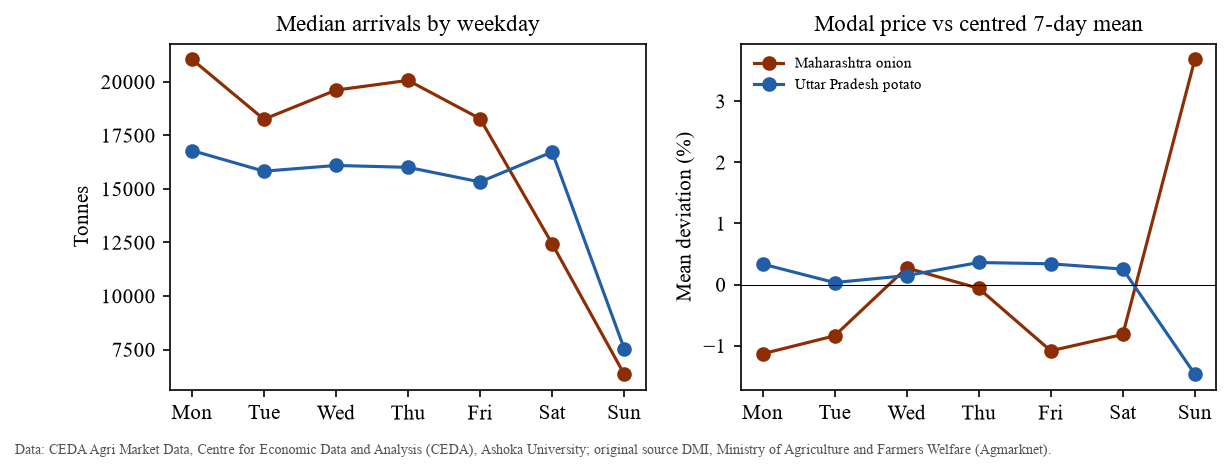

In [15]:
display(Image(filename=str(figs / 'fig12_weekday_composition.png')))

## Price–arrival association and ISS-002

In [16]:
pd.DataFrame(summary['price_arrival']).T

,months,spearman_log_levels,spearman_monthly_log_diff,diff_block_bootstrap_ci95,spearman_lagged_arrival_diff
onion_maharashtra,84,-0.121373,-0.20377,"[-0.410387, -0.054074]","{0: -0.20376978296461104, 1: -0.04363252467866..."
potato_uttar_pradesh,84,-0.535001,-0.596637,"[-0.741313, -0.342513]","{0: -0.5966374207631922, 1: -0.560083151032313..."


In [17]:
pd.DataFrame(summary['iss002']).T

,flagged_rows,modal_position_median_2016-03-04_2017-04-02,modal_position_median_other,max_min_ratio_median_2016-03-04_2017-04-02,max_min_ratio_median_other,flagged_months
onion_maharashtra,0,0.607554,0.622899,2.493936,2.482801,{}
potato_uttar_pradesh,137,0.073821,0.501358,1.093547,1.134074,"{'2016-03': 3, '2016-04': 23, '2016-05': 28, '..."
